# КП — Методи обчислювального інтелекту

Не для кожної задачі є точна формула чи алгоритм. Тоді рішення будують із нечітких правил, налаштовують за даними або шукають еволюційно. Кожна частина практикуму показує один такий метод:

| Частина | Задача | Коли беруть такий метод | Кроки |
|---|---|---|---|
| 1. Нечітка система | оцінка за словесними правилами | є знання експерта словами («якщо дохід високий і стаж середній, то…»), а даних мало | 1–4 |
| 2. Нейро-нечітка модель | прогноз виходу за даними | є дані, але потрібна модель із зрозумілими правилами, а не «чорна скринька» | 5–8 |
| 3. Генетичний алгоритм | розподіл об'єктів між бригадами | треба знайти найкращий варіант серед величезної кількості, а похідних немає і перебір неможливий | 9–11 |

Ноутбук нижче проходить кожен метод на одній задачі. Він не охоплює всіх різновидів методів (є, наприклад, модель Сугено першого порядку, інші функції належності чи оператори ГА), а частину коду дано готовою: ядро моделі Сугено, субтрактивну кластеризацію, запуск ГА, оцінку й ремонт плану, точний розв'язувач. Суть кроків — зібрати метод із заданих частин і прочитати його результат. Документація бібліотек: [scikit-fuzzy](https://scikit-fuzzy.github.io/scikit-fuzzy/) і [PyGAD](https://pygad.readthedocs.io/).

Шаблон веде покроково: у кожному кроці — навіщо він і що зробити, у клітинці з `TODO` — ваш код. Клітинки без `TODO` вже готові, їх лише запустити. Умова вашого варіанта — у `variants/<варіант>/README.md`, дані — у `variants/<варіант>/sample.csv`.

In [3]:
!pip install scikit-fuzzy networkx pygad

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 9.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pygad]


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl
from sklearn.model_selection import train_test_split
from scipy.optimize import minimize, milp, LinearConstraint, Bounds
import pygad

## Частина 1. Нечітка система

### 1. Підсистема

Лінгвістична змінна — величина, значення якої описують словами: «низький», «середній», «високий». Кожне слово — нечітка множина з функцією належності: ступінь від 0 до 1, з яким число належить терму. Сусідні трикутні терми перекриваються, тож число належить двом термам одночасно з різними ступенями.

`automf(3, names=TERMS)` ділить діапазон на три трикутні терми з вершинами на лівому краї, посередині й на правому краї. Правило «ЯКЩО x низький І y високий ТО z середній» пов'язує терми входів із термом виходу, а таблиця 3 × 3 з README — це дев'ять таких правил.

Напишіть функцію `fuzzy_system(x_range, y_range, z_range, table, method)`, яка повертає `ctrl.ControlSystemSimulation` однієї підсистеми:

1. `x_range`, `y_range`, `z_range` — пари (min, max) з README варіанта; кожна змінна — на `np.linspace(min, max, 201)`.
2. `x` і `y` — `ctrl.Antecedent` з назвами `"x"` і `"y"`, `z` — `ctrl.Consequent` з назвою `"z"` і `defuzzify_method=method`.
3. Кожній змінній — `automf(3, names=TERMS)`.
4. `table` — таблиця правил із README як список рядків: `table[i][j]` — терм `z` для `x = TERMS[i]` і `y = TERMS[j]`. У README рядки таблиці — терми `x`, стовпці — терми `y` (заголовок «x \ y»). З неї — дев'ять правил `ctrl.Rule(x[TERMS[i]] & y[TERMS[j]], z[table[i][j]])`, з них — `ctrl.ControlSystem`.

In [6]:
TERMS = ["низький", "середній", "високий"]

def fuzzy_system(x_range, y_range, z_range, table, method="centroid"):
    # Дискретизація просторів змінних
    universe_x = np.linspace(x_range[0], x_range[1], 201)
    universe_y = np.linspace(y_range[0], y_range[1], 201)
    universe_z = np.linspace(z_range[0], z_range[1], 201)

    # Створення антецедентів і консеквента
    x = ctrl.Antecedent(universe_x, "x")
    y = ctrl.Antecedent(universe_y, "y")
    z = ctrl.Consequent(universe_z, "z", defuzzify_method=method)

    # 3 трикутні терми на кожну змінну
    x.automf(3, names=TERMS)
    y.automf(3, names=TERMS)
    z.automf(3, names=TERMS)

    # Формування бази з 9 правил
    rules = []
    for i, tx in enumerate(TERMS):
        for j, ty in enumerate(TERMS):
            out_term = table[i][j]
            rules.append(ctrl.Rule(x[tx] & y[ty], z[out_term]))

    sys = ctrl.ControlSystem(rules)
    return ctrl.ControlSystemSimulation(sys)

### 2. Виведення за Мамдані

Система перетворює числа на входах у число на виході за п'ять етапів:

| Етап | Що відбувається |
|---|---|
| фазифікація | для кожного входу — ступінь належності до кожного терма |
| агрегування умов | сила правила — мінімум ступенів його умов, бо умови з'єднано «І» |
| активізація | терм виходу кожного правила зрізається на рівні сили правила |
| акумуляція | зрізані терми всіх правил об'єднуються максимумом в одну фігуру |
| дефазифікація | фігура перетворюється на число |

Центроїд — абсциса центру ваги фігури: враховує всю фігуру. Середнє максимумів — середина її найвищої ділянки: враховує лише найсильніше правило. Тому на тій самій фігурі вони дають різні числа.

1. Впишіть межі змінних і таблиці правил трьох підсистем зі свого README.
2. Порахуйте вихід 1.1 і вихід 1.2 у точці для кроку 2 з `method="centroid"`: `sim.input["x"]`, `sim.input["y"]`, `sim.compute()`, `sim.output["z"]`. «Подати входи й отримати вихід» знадобиться ще не раз, тож зробіть це функцією.
3. Подайте ці два числа на входи 1.3 — вихід 1.1 на `x`, вихід 1.2 на `y` — і порахуйте вихід 1.3 двічі: з `method="centroid"` і з `method="mom"`. 1.1 і 1.2 перераховувати не треба.
4. Виведіть виходи 1.1, 1.2 і обидва виходи 1.3.

In [7]:
# TODO: межі й таблиці трьох підсистем; виходи 1.1, 1.2 і 1.3 двома методами
# Межі змінних (Варіант 8)
range_1_1_x = (0, 1000)
range_1_1_y = (-20, 40)
range_1_1_z = (0, 10)

range_1_2_x = (0, 8)
range_1_2_y = (0, 500)
range_1_2_z = (0, 10)

range_1_3_x = (0, 10)
range_1_3_y = (0, 10)
range_1_3_z = (0, 200)

# Таблиці правил 3x3
table_1_1 = [
    ["середній", "низький", "середній"],
    ["високий", "низький", "високий"],
    ["високий", "середній", "високий"]
]

table_1_2 = [
    ["середній", "низький", "низький"],
    ["високий", "середній", "низький"],
    ["високий", "високий", "середній"]
]

table_1_3 = [
    ["низький", "низький", "середній"],
    ["низький", "середній", "високий"],
    ["середній", "високий", "високий"]
]

def run_sim(sim, in_x, in_y):
    sim.input["x"] = in_x
    sim.input["y"] = in_y
    sim.compute()
    return sim.output["z"]

# Ініціалізація підсистем
sim_1_1 = fuzzy_system(range_1_1_x, range_1_1_y, range_1_1_z, table_1_1, method="centroid")
sim_1_2 = fuzzy_system(range_1_2_x, range_1_2_y, range_1_2_z, table_1_2, method="centroid")

# Розрахунок у заданій точці (1.1: x=250, y=10; 1.2: x=4.8, y=50)
z_1_1 = run_sim(sim_1_1, 250, 10)
z_1_2 = run_sim(sim_1_2, 4.8, 50)

# Підсистема 1.3 двома методами дефазифікації
sim_1_3_centroid = fuzzy_system(range_1_3_x, range_1_3_y, range_1_3_z, table_1_3, method="centroid")
sim_1_3_mom = fuzzy_system(range_1_3_x, range_1_3_y, range_1_3_z, table_1_3, method="mom")

z_1_3_centroid = run_sim(sim_1_3_centroid, z_1_1, z_1_2)
z_1_3_mom = run_sim(sim_1_3_mom, z_1_1, z_1_2)

print(f"Вихід 1.1 (напруженість графіка): {z_1_1:.4f} балів")
print(f"Вихід 1.2 (вартість покриття піку): {z_1_2:.4f} балів")
print(f"Вихід 1.3 (центроїд): {z_1_3_centroid:.4f} МВт")
print(f"Вихід 1.3 (середнє максимумів, MoM): {z_1_3_mom:.4f} МВт")

Вихід 1.1 (напруженість графіка): 1.9444 балів
Вихід 1.2 (вартість покриття піку): 6.7255 балів
Вихід 1.3 (центроїд): 89.0027 МВт
Вихід 1.3 (середнє максимумів, MoM): 19.4972 МВт


Щоб побачити, чому методи дали різні числа, подивіться, які правила 1.3 спрацювали в цій точці.

Виведіть силу кожного з дев'яти правил 1.3 за таблицею з README, від більшої до меншої. Входи 1.3 — виходи 1.1 і 1.2 з попередньої клітинки.

- ступінь належності входу до терма — `fuzz.interp_membership(universe, mf, значення)`;
- трикутники `automf` — `fuzz.trimf(universe, [a, a, m])`, `[a, m, b]` і `[m, b, b]`, де `a` і `b` — межі змінної, `m` — середина;
- сила правила — мінімум ступенів `x` і `y`; правила із силою 0 не спрацювали.

In [8]:
# TODO: сила дев'яти правил 1.3 у цій точці
ux = np.linspace(range_1_3_x[0], range_1_3_x[1], 201)
uy = np.linspace(range_1_3_y[0], range_1_3_y[1], 201)

# Функції належності для automf(3)
mfx = {
    "низький": fuzz.trimf(ux, [0, 0, 5]),
    "середній": fuzz.trimf(ux, [0, 5, 10]),
    "високий": fuzz.trimf(ux, [5, 10, 10])
}
mfy = {
    "низький": fuzz.trimf(uy, [0, 0, 5]),
    "середній": fuzz.trimf(uy, [0, 5, 10]),
    "високий": fuzz.trimf(uy, [5, 10, 10])
}

deg_x = {t: fuzz.interp_membership(ux, mfx[t], z_1_1) for t in TERMS}
deg_y = {t: fuzz.interp_membership(uy, mfy[t], z_1_2) for t in TERMS}

rule_strengths = []
for i, tx in enumerate(TERMS):
    for j, ty in enumerate(TERMS):
        strength = min(deg_x[tx], deg_y[ty])
        rule_strengths.append((f"ЯКЩО x {tx} І y {ty} ТО z {table_1_3[i][j]}", strength))

rule_strengths.sort(key=lambda item: item[1], reverse=True)
print("Сили правил підсистеми 1.3 у контрольній точці:")
for rule_text, s in rule_strengths:
    print(f"  {rule_text}: {s:.4f}")

Сили правил підсистеми 1.3 у контрольній точці:
  ЯКЩО x низький І y середній ТО z низький: 0.6111
  ЯКЩО x середній І y середній ТО z середній: 0.3889
  ЯКЩО x низький І y високий ТО z середній: 0.3451
  ЯКЩО x середній І y високий ТО z високий: 0.3451
  ЯКЩО x низький І y низький ТО z низький: 0.0000
  ЯКЩО x середній І y низький ТО z низький: 0.0000
  ЯКЩО x високий І y низький ТО z середній: 0.0000
  ЯКЩО x високий І y середній ТО z високий: 0.0000
  ЯКЩО x високий І y високий ТО z високий: 0.0000


### 3. Поверхня

Поверхня показує вихід підсистеми для всіх пар входів одразу. Пологі ділянки — зони, де переважає одне правило; схили — переходи між правилами.

Побудуйте поверхню підсистеми 1.3: вихід (центроїд) на сітці 21 × 21 значень `x` і `y` у їхніх межах. Намалюйте її як `plt.contourf` або 3D-поверхню й підпишіть осі назвами змінних. `plt.contourf(xs, ys, Z)` чекає `Z[i, j]` для `y = ys[i]` і `x = xs[j]`. Зробіть це функцією від таблиці правил: у кроці 4 таку саму поверхню треба побудувати для зміненої таблиці.

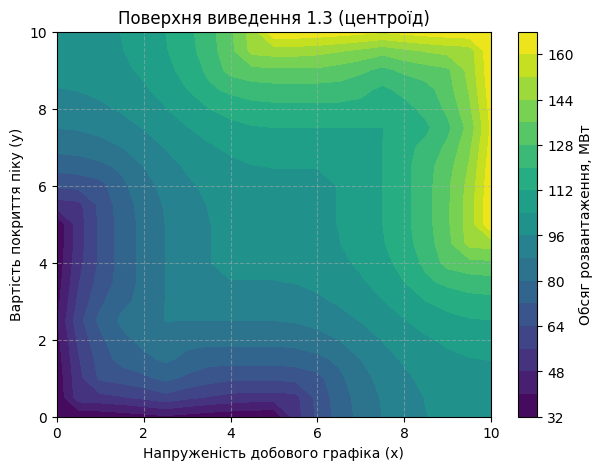

In [10]:
# TODO: поверхня 1.3
def plot_surface(table, title="Поверхня виведення 1.3 (центроїд)"):
    sim = fuzzy_system(range_1_3_x, range_1_3_y, range_1_3_z, table, method="centroid")
    xs = np.linspace(range_1_3_x[0], range_1_3_x[1], 21)
    ys = np.linspace(range_1_3_y[0], range_1_3_y[1], 21)
    Z = np.zeros((len(ys), len(xs)))

    for i, y_val in enumerate(ys):
        for j, x_val in enumerate(xs):
            Z[i, j] = run_sim(sim, x_val, y_val)

    plt.figure(figsize=(7, 5))
    cp = plt.contourf(xs, ys, Z, levels=20, cmap="viridis")
    plt.colorbar(cp, label="Обсяг розвантаження, МВт")
    plt.xlabel("Напруженість добового графіка (x)")
    plt.ylabel("Вартість покриття піку (y)")
    plt.title(title)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.show()
    return xs, ys, Z

xs, ys, Z_orig = plot_surface(table_1_3)

### 4. Одне правило

Кожне правило керує виходом лише там, де воно спрацьовує. Тому зміна однієї клітинки таблиці — одного правила — змінює поверхню лише там, де сила цього правила більша за 0. Для правила з крайніми термами це кут поверхні, для правила із середніми термами — більша її частина, бо середній терм покриває весь діапазон, крім країв.

1. Змініть правило 1.3, як сказано в README для кроку 4. Змінюйте копію таблиці (`[row[:] for row in table]`): стара ще потрібна для порівняння, а зміна вкладеного списку на місці зачепить і її.
2. Порахуйте вихід 1.3 у тій самій точці з `method="centroid"` і з `method="mom"` та виведіть поруч зі старими.
3. Побудуйте поверхню зі зміненим правилом і різницю двох поверхонь.

До зміни:   центроїд = 89.0027, MoM = 19.4972
Після зміни: центроїд = 105.8024, MoM = 100.4314


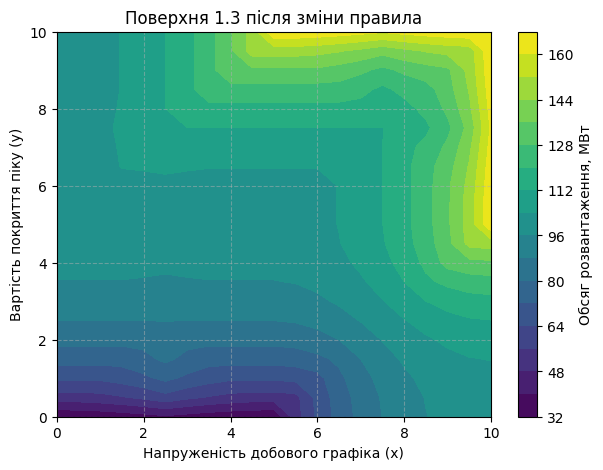

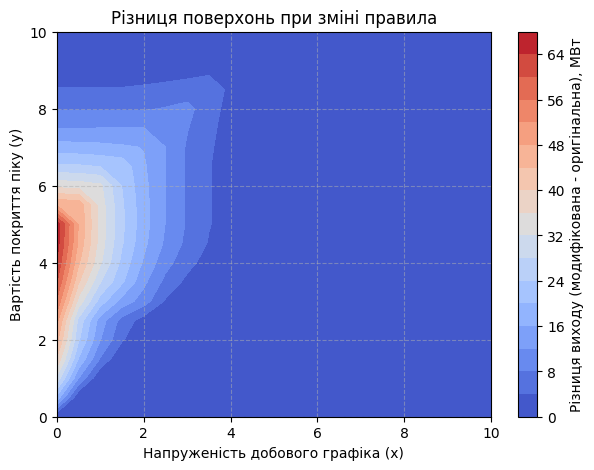

In [11]:
# TODO: змінене правило, вихід 1.3 і поверхні
# Зміна правила: рядок «низький», стовпець «середній» замінити на «середній»
table_1_3_mod = [row[:] for row in table_1_3]
table_1_3_mod[0][1] = "середній"

sim_mod_centroid = fuzzy_system(range_1_3_x, range_1_3_y, range_1_3_z, table_1_3_mod, method="centroid")
sim_mod_mom = fuzzy_system(range_1_3_x, range_1_3_y, range_1_3_z, table_1_3_mod, method="mom")

z_mod_centroid = run_sim(sim_mod_centroid, z_1_1, z_1_2)
z_mod_mom = run_sim(sim_mod_mom, z_1_1, z_1_2)

print(f"До зміни:   центроїд = {z_1_3_centroid:.4f}, MoM = {z_1_3_mom:.4f}")
print(f"Після зміни: центроїд = {z_mod_centroid:.4f}, MoM = {z_mod_mom:.4f}")

_, _, Z_mod = plot_surface(table_1_3_mod, title="Поверхня 1.3 після зміни правила")

# Графік різниці двох поверхонь
plt.figure(figsize=(7, 5))
diff = Z_mod - Z_orig
cp_diff = plt.contourf(xs, ys, diff, levels=20, cmap="coolwarm")
plt.colorbar(cp_diff, label="Різниця виходу (модифікована - оригінальна), МВт")
plt.xlabel("Напруженість добового графіка (x)")
plt.ylabel("Вартість покриття піку (y)")
plt.title("Різниця поверхонь при зміні правила")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## Частина 2. Нейро-нечітка модель

### 5. Дані

Модель Сугено нульового порядку складається з правил «ЯКЩО входи близькі до центру правила ТО y = число». Вихід — середнє висновків правил, зважене ступенями активації. Нейро-нечіткою її роблять параметри — центри, ширини й висновки, — які підбирають за даними, як ваги мережі.

Похибка — RMSE в одиницях виходу. Точка відліку — прогноз середнім значенням навчальної частини: модель, гірша за нього на тестовій частині, нічого корисного не навчилася. Входи й вихід нормують у [0, 1] за навчальною частиною, щоб центри й ширини правил мали однаковий масштаб.

1. Завантажте `sample.csv` свого варіанта: `X` — усі колонки, крім останньої, `y` — остання. Поділ задано нижче.
2. Нормуйте мінімумом і максимумом навчальної частини, для кожного входу окремо (`X_tr.min(axis=0)`): `x_tr`, `x_te` — входи, `t_tr`, `t_te` — вихід. Для тестової частини теж беруть мінімум і максимум навчальної, тож її значення можуть трохи виходити за [0, 1] — це нормально.
3. `y_span = y_tr.max() - y_tr.min()`: на нього множать нормовану похибку, щоб отримати одиниці виходу.
4. Виведіть розміри частин і RMSE прогнозу середнім `y_tr` на навчальній і тестовій частинах.

In [14]:
# TODO: sample.csv свого варіанта, X і y
from google.colab import drive
drive.mount('/content/drive')
data_path = "/content/drive/MyDrive/IAD_KP"

sample = pd.read_csv(f"{data_path}/sample.csv")
print(f"Розмірність sample.csv: {sample.shape}")
X = sample[["active_energy_mwh", "reactive_energy_mvarh", "heat_energy_gcal", "contracted_power_kw"]]
y = sample["service_cost_kuah"]

X_tr, X_te, y_tr, y_te = train_test_split(X.to_numpy(), y.to_numpy(), test_size=0.25, random_state=0)

# Нормування за навчальною вибіркою
x_min, x_max = X_tr.min(axis=0), X_tr.max(axis=0)
y_min, y_max = y_tr.min(), y_tr.max()

x_tr = (X_tr - x_min) / (x_max - x_min)
x_te = (X_te - x_min) / (x_max - x_min)

t_tr = (y_tr - y_min) / (y_max - y_min)
t_te = (y_te - y_min) / (y_max - y_min)
y_span = y_max - y_min

rmse_mean_train = np.sqrt(np.mean((y_tr - y_tr.mean()) ** 2))
rmse_mean_test = np.sqrt(np.mean((y_te - y_tr.mean()) ** 2))

print(f"Розмірності: train = {X_tr.shape[0]}, test = {X_te.shape[0]}")
print(f"RMSE прогнозу середнім: train = {rmse_mean_train:.4f}, test = {rmse_mean_test:.4f}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Розмірність sample.csv: (46, 5)
Розмірності: train = 34, test = 12
RMSE прогнозу середнім: train = 1.0155, test = 0.9242


In [15]:
def unpack(theta, c):
    k = c * x_tr.shape[1]
    return theta[:k].reshape(c, -1), np.exp(theta[k:2 * k]).reshape(c, -1), theta[2 * k:]


def activation(theta, x, c):
    centers, widths, _ = unpack(theta, c)
    z = -0.5 * (((x[:, None, :] - centers[None]) / widths[None]) ** 2).sum(axis=2)
    e = np.exp(z - z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def rmse(theta, x, t, c):
    return float(np.sqrt(np.mean((activation(theta, x, c) @ unpack(theta, c)[2] - t) ** 2)))


def errors(theta, c):
    return rmse(theta, x_tr, t_tr, c) * y_span, rmse(theta, x_te, t_te, c) * y_span


def pack(centers, widths):
    c = len(centers)
    theta = np.concatenate([np.ravel(centers), np.log(np.ravel(widths)), np.zeros(c)])
    w = activation(theta, x_tr, c)
    theta[2 * c * x_tr.shape[1]:] = np.linalg.solve(w.T @ w + 1e-8 * np.eye(c), w.T @ t_tr)
    return theta


def tune(theta, c):
    n = c * x_tr.shape[1]
    bounds = [(-0.05, 1.05)] * n + [(np.log(0.08), np.log(0.8))] * n + [(-0.05, 1.05)] * c
    res = minimize(rmse, np.clip(theta, *np.array(bounds).T), args=(x_tr, t_tr, c),
                   method="L-BFGS-B", bounds=bounds, options={"maxiter": 2000})
    return res.x

Що робить готовий код вище:

| Функція | Що робить |
|---|---|
| `activation` | ступені активації правил: гаусова функція належності на кожен вхід, добуток по входах, нормування до суми 1 (обчислюється через експоненту різниці, щоб не ділити на машинний нуль) |
| `pack` | збирає параметри правил в один вектор; висновки правил рахує методом найменших квадратів, як прямий хід ANFIS |
| `tune` | налаштовує всі параметри мінімізацією RMSE на навчальній частині; центри не виходять за межі даних, ширина — від 0.08 до 0.8 діапазону |
| `errors` | RMSE на навчальній і тестовій частинах в одиницях виходу |

### 6. Субтрактивна кластеризація

Щоб отримати правила з даних, точки навчальної частини кластеризують: кожен кластер стає правилом. Субтрактивна кластеризація сама визначає, скільки кластерів. Кожна точка отримує потенціал — скільки інших точок поблизу. Точка з найбільшим потенціалом стає центром, потенціал її сусідів у межах радіуса впливу `ra` зменшується, і пошук повторюється, доки потенціал не впаде нижче порогу. Малий радіус — багато дрібних кластерів, великий — кілька великих. Так будує базу правил редактор ANFIS у Matlab.

Субтрактивна кластеризація сама обирає кількість правил, але ця кількість сильно залежить від `ra`, а яке `ra` правильне, метод не підказує. Тому далі правила будує c-means із заданою кількістю, а в кроці 8 перевіряють, скільки правил справді потрібно.

Для `ra` = 0.3, 0.5 і 0.8 запустіть `subclust` на `np.column_stack([x_tr, t_tr])` і виведіть, скільки правил дає кожен радіус — стільки рядків у результаті.

In [16]:
def subclust(data, ra, accept=0.5, reject=0.15):
    a, b = 4 / ra ** 2, 4 / (1.5 * ra) ** 2
    potential = np.exp(-a * ((data[:, None, :] - data[None, :, :]) ** 2).sum(-1)).sum(1)
    first, centers = potential.max(), []
    while True:
        k = int(potential.argmax())
        top = potential[k]
        if top < reject * first:
            break
        if top < accept * first:
            nearest = min(np.sqrt(((data[k] - data[c]) ** 2).sum()) for c in centers)
            if nearest / ra + top / first < 1:
                potential[k] = 0
                continue
        centers.append(k)
        potential = np.maximum(potential - top * np.exp(-b * ((data - data[k]) ** 2).sum(1)), 0)
    return data[centers]

In [17]:
# TODO: скільки правил дає кожен ra
train_data_full = np.column_stack([x_tr, t_tr])
for ra_val in [0.3, 0.5, 0.8]:
    centers_sub = subclust(train_data_full, ra_val)
    print(f"Кількість правил для ra = {ra_val}: {len(centers_sub)}")

Кількість правил для ra = 0.3: 19
Кількість правил для ra = 0.5: 8
Кількість правил для ra = 0.8: 3


### 7. Правила з c-means і налаштування

Нечітка кластеризація c-means не визначає кількість кластерів сама: її задають. Зате кожна точка належить кожному кластеру зі своїм ступенем `u`. Кластеризують разом входи й вихід, бо правило має об'єднувати точки, схожі і за входами, і за виходом. Центр правила — перші координати центру кластера, тобто вхідні; ширина на кожен вхід — стандартне відхилення точок від центру, зважене квадратами ступенів `u`.

Налаштування підганяє центри, ширини й висновки під навчальну частину. У трьох правил на чотири входи 27 параметрів, а навчальних рядків — кілька десятків. Такій моделі легко запам'ятати навчальні точки разом із їхнім шумом.

1. Функція `cmeans_rules(c)` нижче майже готова: допишіть ширини. Ширина правила `k` на кожен вхід — `np.sqrt((u[k] ** 2 @ (x_tr - centers[k]) ** 2) / (u[k] ** 2).sum())`.
2. Побудуйте три правила `theta = cmeans_rules(3)` і налаштуйте їх: `theta_tuned = tune(theta, 3)`.
3. Виведіть таблицю RMSE на навчальній і тестовій частинах: прогноз середнім, правила до налаштування (`errors(theta, 3)`) і після.

In [19]:
def cmeans_rules(c):
    cntr, u, *_ = fuzz.cluster.cmeans(np.column_stack([x_tr, t_tr]).T, c=c, m=2.0, error=1e-6, maxiter=1000, seed=0)
    centers = cntr[:, :x_tr.shape[1]]
    # TODO: ширини правил, масив c × кількість входів
    widths = np.array([
        np.sqrt((u[k] ** 2 @ (x_tr - centers[k]) ** 2) / (u[k] ** 2).sum())
        for k in range(c)
    ])
    return pack(centers, np.clip(widths, 0.08, 0.8))

# TODO: theta, theta_tuned і таблиця RMSE
theta = cmeans_rules(3)
theta_tuned = tune(theta, 3)

err_before = errors(theta, 3)
err_after = errors(theta_tuned, 3)

res_table = pd.DataFrame([
    {"Модель": "Прогноз середнім", "Train RMSE": rmse_mean_train, "Test RMSE": rmse_mean_test},
    {"Модель": "c-means (до налаштування)", "Train RMSE": err_before[0], "Test RMSE": err_before[1]},
    {"Модель": "c-means (після tune)", "Train RMSE": err_after[0], "Test RMSE": err_after[1]}
])
display(res_table.round(4))

,Модель,Train RMSE,Test RMSE
0,Прогноз середнім,1.0155,0.9242
1,c-means (до налаштування),0.9701,0.9074
2,c-means (після tune),0.6470,0.9795


### 8. Кількість правил

Кожне нове правило додає параметри. Навчальна похибка від цього зазвичай спадає, а тестова — лише доки нові правила описують закономірність, а не шум. Що більший розрив між тестовою і навчальною похибкою, то сильніше перенавчання.

Для кількості правил від 2 до 6 побудуйте правила `cmeans_rules(c)` і налаштуйте їх. Виведіть таблицю «кількість правил, RMSE на навчальній і тестовій частинах» і побудуйте обидві криві на одному графіку разом із горизонтальною лінією RMSE прогнозу середнім на тестовій частині. Налаштування може зупинитися в локальному мінімумі, тож на кількох десятках рядків криві бувають нерівними; порівнюйте розрив при 2 і при 6 правилах. `theta` і `theta_tuned` із кроку 7 не перезаписуйте: їх використовує самоперевірка.

,Кількість правил,Train RMSE,Test RMSE,Розрив (Test - Train)
0,2,0.9321,0.7965,-0.1356
1,3,0.6470,0.9795,0.3324
2,4,0.5055,0.9409,0.4355
3,5,0.7237,0.9835,0.2598
4,6,0.6095,0.9705,0.3611


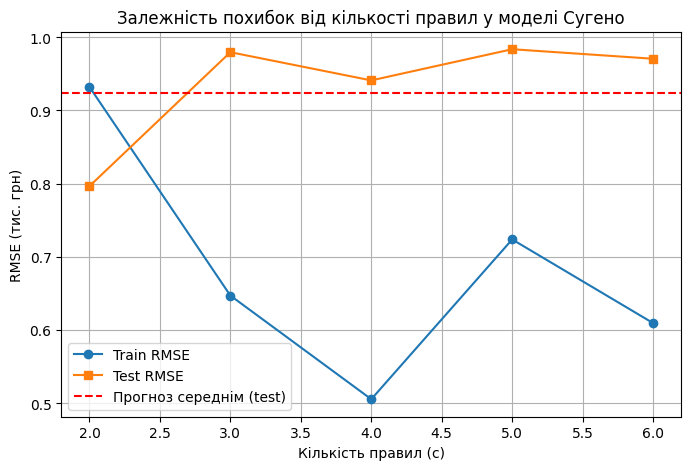

In [20]:
# TODO: таблиця й криві для 2–6 правил
c_values = list(range(2, 7))
train_errors = []
test_errors = []

for c in c_values:
    th = cmeans_rules(c)
    th_t = tune(th, c)
    tr_err, te_err = errors(th_t, c)
    train_errors.append(tr_err)
    test_errors.append(te_err)

rules_perf_df = pd.DataFrame({
    "Кількість правил": c_values,
    "Train RMSE": train_errors,
    "Test RMSE": test_errors,
    "Розрив (Test - Train)": np.array(test_errors) - np.array(train_errors)
})
display(rules_perf_df.round(4))

plt.figure(figsize=(8, 5))
plt.plot(c_values, train_errors, marker="o", label="Train RMSE")
plt.plot(c_values, test_errors, marker="s", label="Test RMSE")
plt.axhline(rmse_mean_test, color="r", linestyle="--", label="Прогноз середнім (test)")
plt.xlabel("Кількість правил (c)")
plt.ylabel("RMSE (тис. грн)")
plt.title("Залежність похибок від кількості правил у моделі Сугено")
plt.grid(True)
plt.legend()
plt.show()

## Частина 3. Розподіл бригад

### 9. Задача й жадібний алгоритм

Об'єкти — рядки `sample.csv`. Кожен об'єкт можна доручити одній із трьох бригад або не брати в план. Час на об'єкт і фонд часу бригад — у README варіанта, втрати, яких уникає обслуговування, — остання колонка. Треба максимізувати суму втрат, яких уникнули, так, щоб жодна бригада не вийшла за свій фонд. Це задача про кілька рюкзаків: перебором її не розв'язати, бо варіантів плану 4 в степені кількості об'єктів.

Жадібний алгоритм бере об'єкти за спаданням відношення «втрати / час» і кладе кожен у першу бригаду, де він ще вміщується, перевіряючи бригади 1, 2, 3 по черзі. Він швидкий, але може зайняти місце, яке краще було б віддати двом іншим об'єктам.

План записується як масив: для кожного об'єкта 0 — не обслуговувати, 1–3 — номер бригади.

1. Впишіть фонд часу трьох бригад і дільник із README варіанта. Порахуйте `t = 0.5 + contracted_power_kw / TIME_DIV` для кожного рядка `sample`; `v` — остання колонка. Беріть усі рядки `sample.csv`, а не лише навчальну частину з кроку 5.
2. Складіть план жадібним алгоритмом, назвіть його `plan_greedy` і виведіть суму, завантаження й перевищення. Порядок об'єктів за спаданням `v / t` дає `np.argsort(-(v / t))`.

Функції нижче вже готові: `load` — завантаження бригад, `overflow` — сумарне перевищення фондів, `value` — сума плану, `repair` — ремонт плану.

In [21]:
# TODO: FUND, TIME_DIV, t і v
FUND = [10.0, 4.0, 4.0]
TIME_DIV = 8.0

t = 0.5 + sample["contracted_power_kw"].to_numpy() / TIME_DIV
v = sample["service_cost_kuah"].to_numpy()

In [22]:
def load(plan):
    return [float(t[plan == b].sum()) for b in (1, 2, 3)]


def overflow(plan):
    return float(sum(max(0.0, used - f) for used, f in zip(load(plan), FUND)))


def value(plan):
    return float(v[plan > 0].sum())


def repair(plan):
    plan = np.asarray(plan, int).copy()
    for b, f in enumerate(FUND, start=1):
        idx = np.flatnonzero(plan == b)
        used = t[idx].sum()
        for i in idx[np.argsort(v[idx] / t[idx])]:
            if used <= f + 1e-9:
                break
            plan[i], used = 0, used - t[i]
    return plan

In [23]:
# TODO: plan_greedy
order = np.argsort(-(v / t))
plan_greedy = np.zeros(len(t), dtype=int)
current_loads = [0.0, 0.0, 0.0]

for idx in order:
    for b_idx in range(3):
        if current_loads[b_idx] + t[idx] <= FUND[b_idx] + 1e-9:
            plan_greedy[idx] = b_idx + 1
            current_loads[b_idx] += t[idx]
            break

print("Жадібний план:")
print(f"Сума: {value(plan_greedy):.4f} тис. грн")
print(f"Завантаження бригад: {[round(x, 2) for x in load(plan_greedy)]}")
print(f"Перевищення фондів: {overflow(plan_greedy):.4f}")

Жадібний план:
Сума: 24.7700 тис. грн
Завантаження бригад: [9.73, 3.72, 3.85]
Перевищення фондів: 0.0000


### 10. Генетичний алгоритм

Генетичний алгоритм тримає популяцію планів. Кожен план оцінюється пристосованістю. Турнірна селекція відбирає кращих із випадкових трійок, рівномірне схрещування бере кожен ген від одного з двох батьків, мутація випадково змінює кілька генів, а чотири найкращі плани переходять у нове покоління без змін. Похідні не потрібні — досить уміти оцінити план.

Обмеження фонду в суму не входить, тож із ним поводяться окремо:

| Спосіб | Як | Ризик |
|---|---|---|
| штраф | пристосованість = сума − 10 · перевищення | малий виступ за фонд може окупитися, і найкращий план буде недопустимим |
| ремонт | перед оцінкою з переповненої бригади знімають найменш вигідні об'єкти; оцінюють уже допустимий план | пошук іде лише серед того, що вміє полагодити ремонт |

Функція `run_ga(fitness)` нижче запускає ГА з параметрами практикуму й повертає найкращий план. Функція пристосованості для `pygad` має вигляд `lambda ga, sol, idx: ...`.

1. ГА з ремонтом: пристосованість — `value(repair(sol))`. Найкращий план полагодьте `repair` і назвіть `plan_repair`.
2. ГА зі штрафом: пристосованість — `value(sol) - 10 * overflow(sol)`. Найкращий план назвіть `plan_penalty`, без ремонту.
3. Для обох планів виведіть суму, завантаження й перевищення.

In [24]:
def run_ga(fitness):
    ga = pygad.GA(num_generations=250, sol_per_pop=120, num_parents_mating=60, num_genes=len(t), gene_type=int,
                  gene_space=[0, 1, 2, 3], fitness_func=fitness, parent_selection_type="tournament", K_tournament=3,
                  crossover_type="uniform", mutation_type="random", mutation_num_genes=max(1, len(t) // 20),
                  keep_elitism=4, random_seed=0, suppress_warnings=True)
    ga.run()
    return np.asarray(ga.best_solution()[0], int)


# TODO: plan_repair
sol_repair = run_ga(lambda ga, sol, idx: value(repair(sol)))
plan_repair = repair(sol_repair)

In [25]:
# TODO: plan_penalty
plan_penalty = run_ga(lambda ga, sol, idx: value(sol) - 10.0 * overflow(sol))

print("ГА з ремонтом:")
print(f"  Сума: {value(plan_repair):.4f}, Завантаження: {[round(x, 2) for x in load(plan_repair)]}, Перевищення: {overflow(plan_repair):.4f}")

print("ГА зі штрафом:")
print(f"  Сума: {value(plan_penalty):.4f}, Завантаження: {[round(x, 2) for x in load(plan_penalty)]}, Перевищення: {overflow(plan_penalty):.4f}")

ГА з ремонтом:
  Сума: 24.7700, Завантаження: [9.79, 3.83, 3.68], Перевищення: 0.0000
ГА зі штрафом:
  Сума: 21.4130, Завантаження: [9.63, 4.09, 3.01], Перевищення: 0.0903


### 11. Точний оптимум

Для кількох десятків об'єктів задачу можна розв'язати точно цілочисловим лінійним програмуванням. Готова функція нижче повертає найкращий можливий план. На практиці такий розв'язувач є не завжди, а в більших задачах він не встигає — тоді й беруть ГА.

Порахуйте `plan_optimum = optimum()` і виведіть таблицю: жадібний алгоритм, ГА з ремонтом, ГА зі штрафом, оптимум — сума, завантаження бригад, перевищення і сума у відсотках від оптимуму.

In [27]:
def optimum():
    n = len(t)
    rows = [np.concatenate([t if b == k else np.zeros(n) for k in range(3)]) for b in range(3)]
    rows += [np.tile(np.eye(n)[i], 3) for i in range(n)]
    res = milp(-np.tile(v, 3), integrality=np.ones(3 * n), bounds=Bounds(0, 1),
               constraints=LinearConstraint(np.array(rows), [0] * (3 + n), list(FUND) + [1] * n))
    return (np.arange(1, 4)[:, None] * np.round(res.x).reshape(3, n)).sum(0).astype(int)

In [28]:
# TODO: plan_optimum і таблиця чотирьох планів
plan_optimum = optimum()

val_opt = value(plan_optimum)
plans = [
    ("Жадібний алгоритм", plan_greedy),
    ("ГА з ремонтом", plan_repair),
    ("ГА зі штрафом", plan_penalty),
    ("Точний оптимум", plan_optimum)
]

summary_plans = []
for p_name, p_arr in plans:
    val_p = value(p_arr)
    summary_plans.append({
        "Метод": p_name,
        "Сума, тис. грн": round(val_p, 4),
        "Завантаження (год)": [round(x, 2) for x in load(p_arr)],
        "Перевищення (год)": round(overflow(p_arr), 4),
        "% від оптимуму": f"{(val_p / val_opt) * 100:.2f}%"
    })

display(pd.DataFrame(summary_plans))

,Метод,"Сума, тис. грн",Завантаження (год),Перевищення (год),% від оптимуму
0,Жадібний алгоритм,24.770,"[9.73, 3.72, 3.85]",0.0000,99.73%
1,ГА з ремонтом,24.770,"[9.79, 3.83, 3.68]",0.0000,99.73%
2,ГА зі штрафом,21.413,"[9.63, 4.09, 3.01]",0.0903,86.21%
3,Точний оптимум,24.837,"[9.97, 3.88, 3.76]",0.0000,100.00%


### 12. Самоперевірка й збереження

Якщо якась перевірка падає, поверніться до відповідного кроку.

In [29]:
plan = pd.DataFrame({"row": np.arange(len(t)), "brigade": np.asarray(plan_repair, int)})

assert len(t) == len(v) == len(plan) == len(sample), "t, v і план мають мати рядок на кожен об'єкт sample.csv"
assert tuple(FUND) in [(6, 6, 6), (7, 6, 5), (7, 7, 4), (8, 5, 5), (8, 6, 4), (8, 7, 3), (9, 5, 4), (9, 6, 3), (10, 4, 4), (10, 5, 3)] and TIME_DIV in (8, 10, 12), "фонди бригад і дільник — з README варіанта, фонди в порядку бригад 1, 2, 3"
assert plan["brigade"].isin([0, 1, 2, 3]).all(), "бригада — 0, 1, 2 або 3"
assert overflow(plan_repair) == 0, "план ГА з ремонтом перевищує фонд часу"
assert value(plan_repair) >= value(plan_greedy) - 1e-9, "ГА з ремонтом гірший за жадібний алгоритм: перевірте параметри з кроку 10"
assert value(plan_repair) <= value(plan_optimum) + 1e-9, "сума більша за оптимум: перевірте t, v і FUND"
assert errors(theta_tuned, 3)[0] < errors(theta, 3)[0], "налаштування не знизило навчальну похибку"

plan.to_csv("plan.csv", index=False)
print("усе гаразд: сума", round(value(plan_repair), 3), "з оптимуму", round(value(plan_optimum), 3))

from google.colab import files
files.download("plan.csv")

усе гаразд: сума 24.77 з оптимуму 24.837


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>